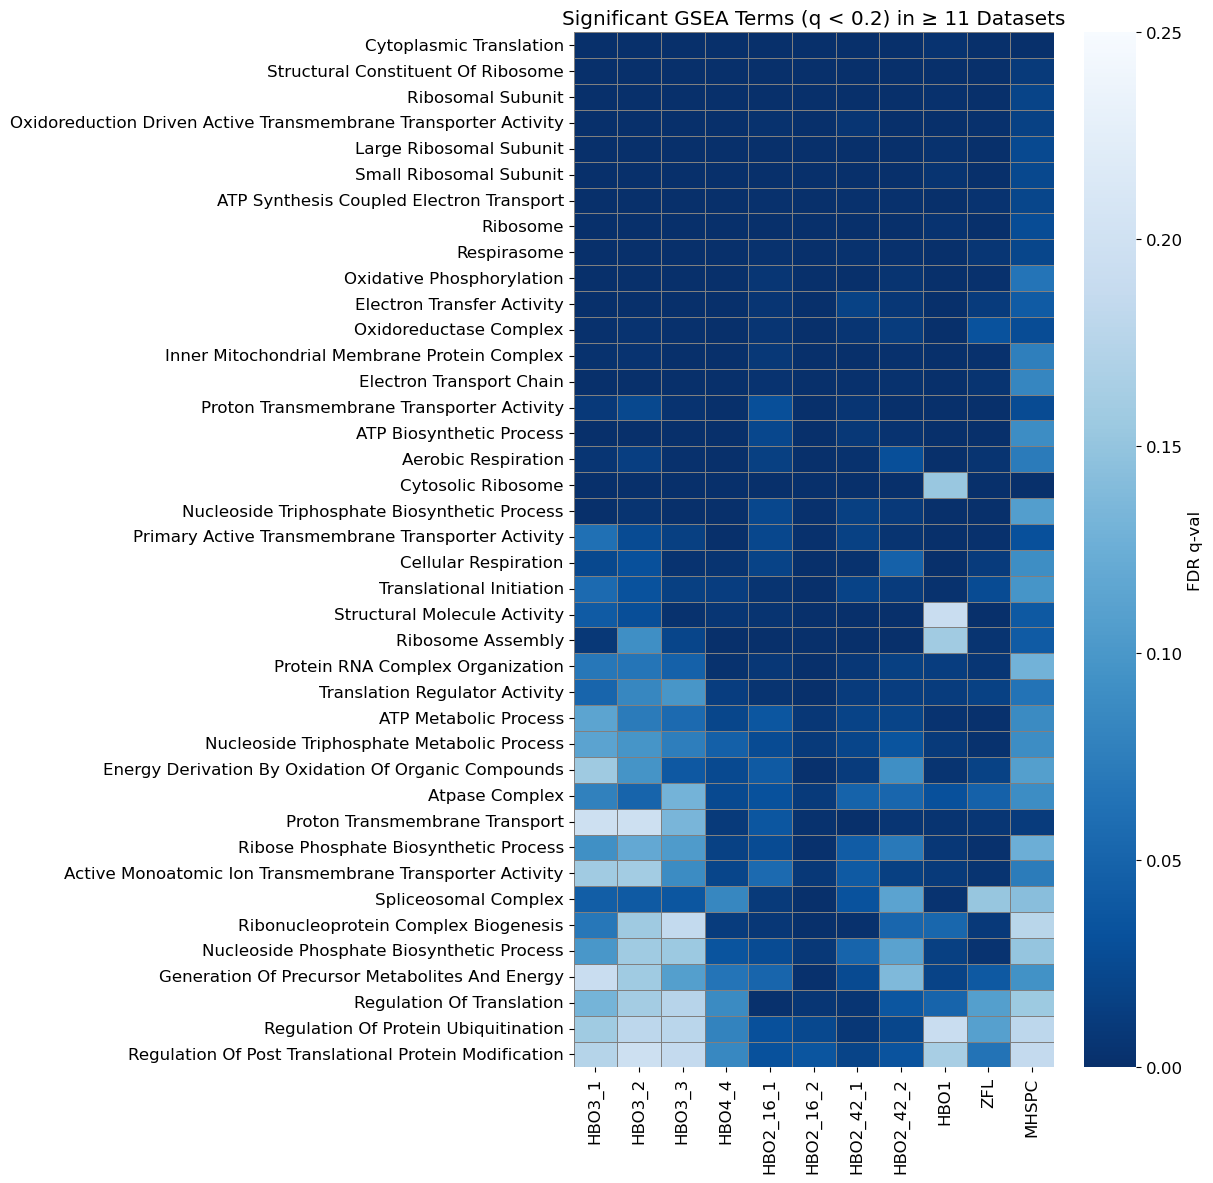

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import matplotlib as mpl
mpl.rcParams.update({'font.size': 12}) 

# --- Parameters ---
output_dir = '/Users/proth/Downloads/GSEA/gsea_results_mi/'
threshold = 0.20
min_datasets = 11

# --- GO Term Cleaning ---
def clean_go_term(name):
    name = re.sub(r'^[^_]*_', '', name)  # Remove prefix like GOBP_, GOCC_
    name = name.replace('_', ' ')
    name = name.title()
    name = re.sub(r'\bDna\b', 'DNA', name)
    name = re.sub(r'\bRna\b', 'RNA', name)
    name = re.sub(r'\bAtp\b', 'ATP', name)
    return name

# --- Dataset Rename and Column Order ---
rename_dict = {
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO4_4",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "treutlein": "HBO1",
    "weinreb": "MHSPC",
    "junker": "ZFL",
}
column_order = [
    "HBO3_1", "HBO3_2", "HBO3_3", "HBO4_4",
    "HBO2_16_1", "HBO2_16_2", "HBO2_42_1", "HBO2_42_2",
    "HBO1", "ZFL", "MHSPC",
]

# --- Collect significant terms ---
all_significant_entries = []

for dataset_dir in os.listdir(output_dir):
    dataset_path = os.path.join(output_dir, dataset_dir)
    if os.path.isdir(dataset_path):
        subdirs = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]
        if len(subdirs) == 1:
            subdir_path = os.path.join(dataset_path, subdirs[0])
            for file_name in os.listdir(subdir_path):
                if file_name.startswith('gsea_report_for_na_pos_') and file_name.endswith('.tsv'):
                    result_file = os.path.join(subdir_path, file_name)
                    if os.path.exists(result_file):
                        df = pd.read_csv(result_file, sep='\t')
                        sig_df = df[df['FDR q-val'] < threshold]
                        for _, row in sig_df.iterrows():
                            all_significant_entries.append({
                                'dataset': dataset_dir,
                                'term': row['NAME'],
                                'FDR q-val': row['FDR q-val']
                            })

# --- Pivot into matrix ---
significant_df_all = pd.DataFrame(all_significant_entries)
qval_matrix = significant_df_all.pivot(index='term', columns='dataset', values='FDR q-val')
qval_matrix_filtered = qval_matrix[qval_matrix.notna().sum(axis=1) >= min_datasets]
qval_matrix_plot = qval_matrix_filtered.fillna(1.0)

# --- Rename and reorder columns ---
qval_matrix_plot = qval_matrix_plot.rename(columns=rename_dict)
qval_matrix_plot = qval_matrix_plot[[col for col in column_order if col in qval_matrix_plot.columns]]

# --- Clean GO term names ---
qval_matrix_plot.index = [clean_go_term(term) for term in qval_matrix_plot.index]

# --- Sort rows by mean q-value ---
qval_matrix_plot = qval_matrix_plot.loc[qval_matrix_plot.mean(axis=1).sort_values().index]

# --- Add count of significant datasets ---
qval_matrix_plot["# Significant Datasets"] = (qval_matrix_filtered.notna().sum(axis=1)).loc[qval_matrix_filtered.index]
qval_matrix_plot["# Significant Datasets"] = qval_matrix_plot["# Significant Datasets"].values  # Ensure alignment

# --- Save to TSV ---
qval_matrix_plot.to_csv('filtered_qval_matrix_with_clean_names.tsv', sep='\t')

# --- Plot heatmap (without the count column) ---
plt.figure(figsize=(12, max(6, 0.3 * len(qval_matrix_plot))))
sns.heatmap(
    qval_matrix_plot.drop(columns=["# Significant Datasets"]),
    cmap='Blues_r',
    annot=False,
    cbar_kws={'label': 'FDR q-val'},
    vmin=0,
    vmax=0.25,
    linewidths=0.5,
    linecolor='gray'
)
plt.title(f'Significant GSEA Terms (q < {threshold}) in ≥ {min_datasets} Datasets')
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig("gsea_heatmap_cleaned_sorted_MI.pdf", bbox_inches="tight")
plt.show()

# Filter for terms with at least N datasets below threshold
sig_counts = significant_df_all.groupby("term")["dataset"].nunique()
selected_terms = sig_counts[sig_counts >= min_datasets].index

# >>> ADD THIS: keep the exact term keys used for the heatmap (pre-cleaning)
HEATMAP_TERMS = set(selected_terms)


In [5]:
CATEGORIES = {

    "Metabolism & Mitochondria": [
        "GOBP_AEROBIC_RESPIRATION",
        "GOBP_CELLULAR_RESPIRATION",
        "GOBP_ELECTRON_TRANSPORT_CHAIN",
        "GOBP_OXIDATIVE_PHOSPHORYLATION",
        "GOBP_ATP_SYNTHESIS_COUPLED_ELECTRON_TRANSPORT",
        "GOBP_PROTON_TRANSMEMBRANE_TRANSPORT",
        "GOBP_ENERGY_DERIVATION_BY_OXIDATION_OF_ORGANIC_COMPOUNDS",
        "GOBP_GENERATION_OF_PRECURSOR_METABOLITES_AND_ENERGY",
        "GOBP_ATP_BIOSYNTHETIC_PROCESS",
        "GOBP_ATP_METABOLIC_PROCESS",
        "GOCC_INNER_MITOCHONDRIAL_MEMBRANE_PROTEIN_COMPLEX",
        "GOCC_RESPIRASOME",
        "GOCC_OXIDOREDUCTASE_COMPLEX",
        "GOMF_ELECTRON_TRANSFER_ACTIVITY",
        "GOBP_GLYCOLYTIC_PROCESS_THROUGH_GLUCOSE_6_PHOSPHATE",
        "GOBP_MITOCHONDRIAL_ELECTRON_TRANSPORT_NADH_TO_UBIQUINONE",
        "GOBP_NADH_DEHYDROGENASE_COMPLEX_ASSEMBLY",
        "GOBP_PROTON_MOTIVE_FORCE_DRIVEN_ATP_SYNTHESIS",
        "GOBP_NADH_METABOLIC_PROCESS",
        "GOBP_NAD_METABOLIC_PROCESS",
        "GOBP_NAD_CATABOLIC_PROCESS",
        "GOCC_CYTOCHROME_COMPLEX",
        "GOCC_NADH_DEHYDROGENASE_COMPLEX",
        "GOCC_RESPIRATORY_CHAIN_COMPLEX_IV",
        "GOMF_NADH_DEHYDROGENASE_UBIQUINONE_ACTIVITY",
        "GOMF_OXIDOREDUCTASE_ACTIVITY_ACTING_ON_NAD_P_H",
        "GOMF_OXIDOREDUCTASE_ACTIVITY_ACTING_ON_NAD_P_H_QUINONE_OR_SIMILAR_COMPOUND_AS_ACCEPTOR",
    ],

    "Ribosome & Translation": [
        "GOBP_CYTOPLASMIC_TRANSLATION",
        "GOBP_TRANSLATIONAL_INITIATION",
        "GOBP_REGULATION_OF_TRANSLATION",
        "GOBP_RIBOSOME_ASSEMBLY",
        "GOCC_RIBOSOME",
        "GOCC_CYTOSOLIC_RIBOSOME",
        "GOCC_RIBOSOMAL_SUBUNIT",
        "GOCC_LARGE_RIBOSOMAL_SUBUNIT",
        "GOCC_SMALL_RIBOSOMAL_SUBUNIT",
        "GOMF_STRUCTURAL_CONSTITUENT_OF_RIBOSOME",
        "GOMF_TRANSLATION_REGULATOR_ACTIVITY",
        "GOMF_STRUCTURAL_MOLECULE_ACTIVITY",
        "GOCC_EUKARYOTIC_TRANSLATION_INITIATION_FACTOR_3_COMPLEX",
        "GOMF_TRANSLATION_INITIATION_FACTOR_ACTIVITY",
    ],

    "RNA / RNP Processing": [
        "GOBP_PROTEIN_RNA_COMPLEX_ORGANIZATION",
        "GOBP_RIBONUCLEOPROTEIN_COMPLEX_BIOGENESIS",
        "GOCC_SPLICEOSOMAL_COMPLEX",
        "GOCC_U1_SNRNP",
        "GOCC_U2_SNRNP",
    ],

    "Protein Homeostasis": [
        "GOBP_REGULATION_OF_POST_TRANSLATIONAL_PROTEIN_MODIFICATION",
        "GOBP_REGULATION_OF_PROTEIN_UBIQUITINATION",
    ],

    "Transport & Membranes": [
        "GOCC_ATPASE_COMPLEX",
        "GOMF_PRIMARY_ACTIVE_TRANSMEMBRANE_TRANSPORTER_ACTIVITY",
        "GOMF_ACTIVE_MONOATOMIC_ION_TRANSMEMBRANE_TRANSPORTER_ACTIVITY",
        "GOMF_OXIDOREDUCTION_DRIVEN_ACTIVE_TRANSMEMBRANE_TRANSPORTER_ACTIVITY",
        "GOMF_PROTON_TRANSMEMBRANE_TRANSPORTER_ACTIVITY",
        "GOBP_NUCLEOSIDE_PHOSPHATE_BIOSYNTHETIC_PROCESS",
        "GOBP_NUCLEOSIDE_TRIPHOSPHATE_BIOSYNTHETIC_PROCESS",
        "GOBP_NUCLEOSIDE_TRIPHOSPHATE_METABOLIC_PROCESS",
        "GOBP_RIBOSE_PHOSPHATE_BIOSYNTHETIC_PROCESS",
    ],

    "Immune / Multi-organism": [
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PEPTIDE_ANTIGEN_VIA_MHC_CLASS_I",
        "GOBP_ANTIMICROBIAL_HUMORAL_IMMUNE_RESPONSE_MEDIATED_BY_ANTIMICROBIAL_PEPTIDE",
        "GOMF_MHC_PROTEIN_BINDING",
        "GOBP_DISRUPTION_OF_ANATOMICAL_STRUCTURE_IN_ANOTHER_ORGANISM",
    ],

    "Development / Differentiation": [
        "GOBP_BINDING_OF_SPERM_TO_ZONA_PELLUCIDA",
        "GOBP_SPERM_EGG_RECOGNITION",
    ],

    "Signaling / Physiology": [
        "GOBP_POSITIVE_REGULATION_OF_BLOOD_PRESSURE",
    ],

    "Metabolism (non-mitochondrial)": [
        "GOBP_ALDEHYDE_BIOSYNTHETIC_PROCESS",
        "GOMF_MONOCARBOXYLIC_ACID_BINDING",
    ],
}


Conserved terms: 40


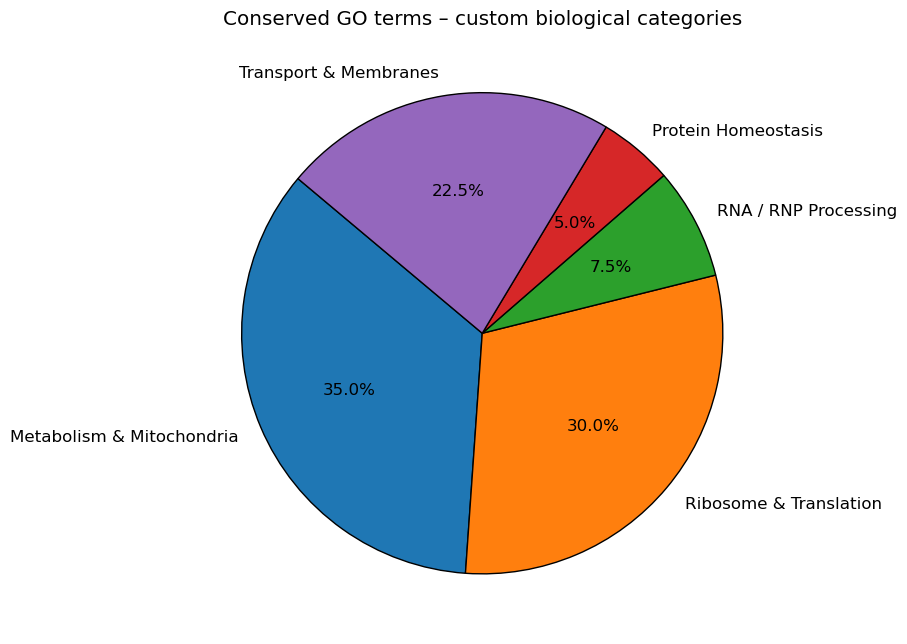

In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# ----------------------------
# USER PARAMS
# ----------------------------
output_dir   = "gsea_results_MI"  # or IG folder
threshold    = 0.2
MIN_DATASETS = None                         # None = require ALL datasets

OUT_PDF      = "MI_custom_categories_conserved.pdf"

# ----------------------------
# Collect conserved POS terms
# ----------------------------
KEEP_PREFIXES = ("GOBP_", "GOMF_", "GOCC_")

def keep_term(t):
    return isinstance(t, str) and t.startswith(KEEP_PREFIXES)

entries = []
datasets = set()

for ds in os.listdir(output_dir):
    p = os.path.join(output_dir, ds)
    if not os.path.isdir(p):
        continue
    subdirs = [d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d))]
    if len(subdirs) != 1:
        continue
    sd = os.path.join(p, subdirs[0])
    for fn in os.listdir(sd):
        if fn.startswith("gsea_report_for_na_pos_") and fn.endswith(".tsv"):
            datasets.add(ds)
            df = pd.read_csv(os.path.join(sd, fn), sep="\t")
            df = df[df["FDR q-val"] < threshold]
            df = df[df["NAME"].apply(keep_term)]
            for t in df["NAME"]:
                entries.append({"dataset": ds, "term": t})

df = pd.DataFrame(entries)
counts = df.groupby("term")["dataset"].nunique()

required = len(datasets) if MIN_DATASETS is None else MIN_DATASETS
terms = counts[counts >= required].index.tolist()

print(f"Conserved terms: {len(terms)}")


# ----------------------------
# Assign + plot
# ----------------------------
term_to_cat = {t: c for c, ts in CATEGORIES.items() for t in ts}
assigned = [term_to_cat[t] for t in terms]

counts = Counter(assigned)
# ----------------------------
# Assign categories
# ----------------------------
term_to_cat = {t: c for c, ts in CATEGORIES.items() for t in ts}
assigned = [term_to_cat[t] for t in terms]

counts = Counter(assigned)

# ----------------------------
# Filter zero-count categories
# ----------------------------
labels = []
sizes = []

for cat in CATEGORIES.keys():  # keep original order
    n = counts.get(cat, 0)
    if n > 0:
        labels.append(cat)
        sizes.append(n)

# ----------------------------
# Fixed, reproducible colors per category
# ----------------------------
BASE_COLORS = {
    "Metabolism & Mitochondria": "#1f77b4",
    "Ribosome & Translation": "#ff7f0e",
    "RNA / RNP Processing": "#2ca02c",
    "Protein Homeostasis": "#d62728",
    "Transport & Membranes": "#9467bd",
    "Immune / Multi-organism": "#8c564b",
    "Development / Differentiation": "#e377c2",
    "Signaling / Physiology": "#7f7f7f",
    "Metabolism (non-mitochondrial)": "#bcbd22",
}

colors = [BASE_COLORS[c] for c in labels]

# ----------------------------
# Plot
# ----------------------------
plt.figure(figsize=(9, 9))
plt.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    wedgeprops={"edgecolor": "black", "linewidth": 1},
)
plt.title("Conserved GO terms – custom biological categories")
plt.tight_layout()
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()

